# Sensibilité au prix : segmentation par delta de GNoS entre deux périodes

**Question :** après un changement de prix, quels profils sociodémographiques voient leur GNoS
baisser le plus (S+), le moins (S-), ou entre les deux (S) ?

**Méthode volontairement simple, sans modèle statistique :**

1. On croise les variables sociodémographiques choisies. Chaque combinaison de modalités forme une
   **cellule**, par exemple `[18, 35) | celibataire | locataire | salarie`.
2. Pour chaque cellule, on calcule le **delta de GNoS** entre la période AVANT et la période APRÈS.
3. On trie les cellules par delta et on teste **toutes** les façons de les couper en trois blocs, en appliquant deux règles :
   - **Règle 1 :** maximiser l'écart entre les deltas des trois segments ;
   - **Règle 2 :** chaque segment doit être suffisamment alimenté, en part de la population et en effectif minimal dans chaque période.
4. Le bloc dont le GNoS baisse le plus devient **S+** (le plus sensible). Le bloc dont il baisse le moins devient **S-**.

Ce notebook ne modifie pas le script `credit-segments` existant. Il utilise le module
`credit_segments/delta.py`.

> Sans paramétrage, le notebook tourne sur des **données synthétiques** : hausse de +1 point de taux au 1er juillet 2024.
> Pour l'utiliser sur vos données, modifiez uniquement la cellule **Paramètres**.

In [1]:
import sys
from pathlib import Path

# Permet d'exécuter le notebook sans installation du package (pip install -e .)
racine = Path.cwd().resolve()
racine = racine.parent if racine.name == "notebooks" else racine
if str(racine / "src") not in sys.path:
    sys.path.insert(0, str(racine / "src"))

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from credit_segments import delta as ds  # noqa: E402

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## 1. Paramètres : la seule cellule à modifier

### À quoi servent ces paramètres ? (et pourquoi ils remplacent ceux de l'ancien script)

L'ancien script (`credit-segments fit`) estimait une **régression** du booking sur le taux dans
chaque segment. Ses paramètres étaient liés à ce modèle :

| Ancien paramètre | Rôle dans l'ancien script | Dans ce notebook |
|---|---|---|
| `--features` | Variables utilisées pour construire les règles des segments | → `VARIABLES_SOCIODEMO` |
| `--controls` | Variables **numériques** (ex. score de risque) ajoutées à la régression pour que l'effet du taux ne soit pas confondu avec le risque | **Supprimé** : pas de régression |
| `--profile` | Variables uniquement **descriptives**, sans rôle dans la construction | Les variables sociodémographiques servent à la fois à construire et à décrire |
| `--min-share` | Part minimale de chaque segment | → `PART_MIN_PAR_SEGMENT` (règle 2) |
| `--min-approved` | Nombre minimal d'offres approuvées pour estimer la régression | → `EFFECTIF_MIN_SEGMENT_PAR_PERIODE` (règle 2) |
| `--min-rate-std` | Dispersion minimale des taux pour estimer une pente | **Supprimé** : pas de pente estimée |
| `--train-fraction` | Découpage apprentissage / validation | **Remplacé** par vos deux périodes `PERIODE_AVANT` / `PERIODE_APRES` |

### Variables sociodémographiques : mettez-en autant que vous voulez

`VARIABLES_SOCIODEMO` accepte **n'importe quelle liste** de colonnes catégorielles. L'algorithme :
- convertit chaque colonne en texte et traite les valeurs manquantes comme une modalité `(manquant)` ;
- découpe en classes les variables **continues** déclarées dans `DECOUPAGE_VARIABLES_CONTINUES`, par exemple l'âge en tranches ;
- croise toutes les variables pour former les cellules ;
- refuse une variable de plus de 15 modalités : il faut alors la regrouper.

**Attention au nombre de cellules.** 4 variables à 3 modalités donnent 81 cellules. 6 variables à 5 modalités en donnent 15 625. Plus il y a de cellules, plus chacune est petite et plus son delta est bruité.
Les cellules trop petites (`EFFECTIF_MIN_CELLULE_PAR_PERIODE`) reçoivent pour le tri le delta d'une cellule plus large.
On retire d'abord la **dernière** variable de la liste. **Placez donc les variables les plus importantes en premier.**

In [2]:
# ============================ PARAMÈTRES ==================================

# --- 1. Données ------------------------------------------------------------
CHEMIN_DONNEES = None            # None = données synthétiques ; sinon "data/mon_fichier.csv"
FILTRE = {"product": "renovation"}  # ex. {"product": "auto"} ; {} pour ne rien filtrer
COLONNE_DATE = "date"            # date de la demande
COLONNE_GNOS = "gnos"            # GNoS de la ligne (0 si non financé)
COLONNE_TAUX = "rate_pp"         # optionnel : vérifier que le prix a bien bougé (None si absent)
COLONNE_BOOKED = "booked"        # optionnel : décomposer volume / ticket (None si absent)

# --- 2. Les deux périodes comparées (bornes incluses) ---------------------
PERIODE_AVANT = ("2024-01-01", "2024-06-30")
PERIODE_APRES = ("2024-07-01", "2024-12-31")
SENS_CHANGEMENT_PRIX = "hausse"  # "hausse" : S+ = plus forte baisse de GNoS
                                 # "baisse" : S+ = plus forte hausse de GNoS

# --- 3. Variables sociodémographiques (autant que souhaité, les plus importantes d'abord)
VARIABLES_SOCIODEMO = ["age", "statut_marital", "logement", "emploi"]
DECOUPAGE_VARIABLES_CONTINUES = {  # bornes [incluse ; exclue)
    "age": [18, 35, 55, 120],
}

# --- 4. Mesure du delta ---------------------------------------------------
METRIQUE = "gnos_total"          # "gnos_total" : capte aussi la baisse du nombre de demandes
                                 # "gnos_par_demande" : neutralise le volume de demandes
TYPE_DELTA = "relatif"           # "relatif" (%, comparable entre groupes) ou "absolu"
                                 # ("absolu" seulement avec gnos_par_demande)

# --- 5. Règle 2 : taille minimale des segments ---------------------------
PART_MIN_PAR_SEGMENT = 0.20               # chaque segment >= 20 % des demandes (2 périodes)
EFFECTIF_MIN_SEGMENT_PAR_PERIODE = 300    # et >= 300 demandes AVANT et >= 300 APRÈS
EFFECTIF_MIN_CELLULE_PAR_PERIODE = 30     # en dessous : repli sur une cellule plus large

# --- 6. Robustesse --------------------------------------------------------
N_BOOTSTRAP = 300          # intervalles de confiance des deltas
N_PERMUTATIONS = 200       # test « le hasard ferait-il aussi bien ? »
LANCER_PLACEBO = True      # refaire l'analyse sur 2 périodes SANS changement de prix
PLACEBO_AVANT = ("2024-01-01", "2024-03-31")
PLACEBO_APRES = ("2024-04-01", "2024-06-30")
GRAINE = 42

# --- 7. Export (agrégats uniquement ; dossier ignoré par Git) ------------
DOSSIER_RESULTATS = "results/delta_gnos"

In [3]:
cfg = ds.Config(
    variables_sociodemo=VARIABLES_SOCIODEMO,
    periode_avant=PERIODE_AVANT,
    periode_apres=PERIODE_APRES,
    colonne_date=COLONNE_DATE,
    colonne_gnos=COLONNE_GNOS,
    colonne_taux=COLONNE_TAUX,
    colonne_booked=COLONNE_BOOKED,
    decoupage_continu=DECOUPAGE_VARIABLES_CONTINUES,
    metrique=METRIQUE,
    delta=TYPE_DELTA,
    sens_prix=SENS_CHANGEMENT_PRIX,
    part_min_segment=PART_MIN_PAR_SEGMENT,
    effectif_min_segment_par_periode=EFFECTIF_MIN_SEGMENT_PAR_PERIODE,
    effectif_min_cellule_par_periode=EFFECTIF_MIN_CELLULE_PAR_PERIODE,
)
cfg.verifier()
UNITE = ds.unite_delta(cfg)

# Couleurs fixes par segment (identité, jamais réattribuées) + gris pour la population
COULEURS = {"S+": "#eb6834", "S": "#2a78d6", "S-": "#1baf7a", "Total": "#7a7974"}
ENCRE, ENCRE_2, GRILLE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ENCRE_2, "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2,
    "ytick.color": ENCRE_2, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5,
})


def ecarter(valeurs, ecart_min):
    # Positions d étiquettes décalées pour éviter les chevauchements (ordre conservé)
    ordre = np.argsort(valeurs)
    pos = np.array(valeurs, dtype=float)
    for a, b in zip(ordre[:-1], ordre[1:]):
        pos[b] = max(pos[b], pos[a] + ecart_min)
    return pos + (np.mean(valeurs) - pos.mean())  # recentre le bloc d'étiquettes

## 2. Chargement et contrôles qualité

Format attendu : **une ligne = une demande**, refus et abandons compris, avec GNoS = 0 si non financé.
Si votre fichier ne contient que les crédits financés, utilisez `METRIQUE = "gnos_total"` :
le delta relatif du GNoS total reste interprétable. `gnos_par_demande` mesurerait alors seulement le ticket moyen.

In [4]:
if CHEMIN_DONNEES is None:
    brut = ds.demo_deux_periodes()
else:
    brut = pd.read_csv(CHEMIN_DONNEES)

for colonne, valeur in FILTRE.items():
    brut = brut.loc[brut[colonne] == valeur]

donnees = ds.preparer(brut, cfg)

controle = (
    donnees.groupby("periode")
    .agg(demandes=("_gnos", "size"), gnos_total=("_gnos", "sum"),
         part_gnos_nul=("_gnos", lambda s: (s == 0).mean()),
         date_min=("_date", "min"), date_max=("_date", "max"))
    .reindex(["avant", "apres"])
)
print(f"{len(brut):,} lignes après filtre ; {len(donnees):,} dans les deux périodes "
      f"({len(brut) - len(donnees):,} hors périodes, ignorées).")
controle

20,000 lignes après filtre ; 20,000 dans les deux périodes (0 hors périodes, ignorées).


,demandes,gnos_total,part_gnos_nul,date_min,date_max
periode,,,,,
avant,9958,58684546.0,0.548504,2024-01-01,2024-06-30
apres,10042,39226729.0,0.686915,2024-07-01,2024-12-31


In [5]:
# Modalités par variable : effectifs AVANT / APRÈS et manquants
qualite = []
for v in VARIABLES_SOCIODEMO:
    t = donnees.groupby([v, "periode"]).size().unstack().reindex(columns=["avant", "apres"]).fillna(0)
    for modalite, r in t.iterrows():
        qualite.append({"variable": v, "modalite": modalite,
                        "n_avant": int(r.avant), "n_apres": int(r.apres),
                        "evolution_mix_pp": 100 * (r.apres / t.apres.sum() - r.avant / t.avant.sum())})
qualite = pd.DataFrame(qualite)
nb_cellules_theorique = np.prod([donnees[v].nunique() for v in VARIABLES_SOCIODEMO])
print(f"Cellules possibles : {nb_cellules_theorique} ; observées : {donnees.cellule.nunique()}")
print("evolution_mix_pp : variation du poids de la modalité entre les périodes. Un changement de mix "
      "important signale un changement de population (marketing, canal, politique de risque).")
qualite.style.format({"evolution_mix_pp": "{:+.1f}"}).background_gradient(
    subset="evolution_mix_pp", cmap="RdBu_r", vmin=-5, vmax=5)

Cellules possibles : 54 ; observées : 42
evolution_mix_pp : variation du poids de la modalité entre les périodes. Un changement de mix important signale un changement de population (marketing, canal, politique de risque).


,variable,modalite,n_avant,n_apres,evolution_mix_pp
0,age,"[18, 35)",2655,2766,+0.9
1,age,"[35, 55)",3155,3213,+0.3
2,age,"[55, 120)",4148,4063,-1.2
3,statut_marital,celibataire,3999,3972,-0.6
4,statut_marital,couple,4468,4457,-0.5
5,statut_marital,divorce,1491,1613,+1.1
6,logement,locataire,5264,5367,+0.6
7,logement,proprietaire,4694,4675,-0.6
8,emploi,independant,1100,1162,+0.5
9,emploi,retraite,2454,2410,-0.6


## 3. Segmentation : application des deux règles

In [6]:
cellules, donnees, score = ds.segmenter(donnees, cfg)
resume = ds.synthese(donnees, cfg)

repli = cellules.groupby("niveau_repli").n_total.sum() / cellules.n_total.sum()
print("Origine du delta utilisé pour le tri (part des demandes) :")
print(repli.map("{:.1%}".format).to_string())
print(f"\nScore (variance inter-segments des deltas, pondérée) : {score:,.1f}")
print("Règle 2 respectée :", bool(resume.drop("Total")[["part_ok", "effectif_ok"]].all().all()))

colonnes = ["n_avant", "n_apres", "part_population", "gnos_avant", "gnos_apres", "delta"]
colonnes += [c for c in ["delta_taux_pp", "conversion_avant", "conversion_apres",
                         "ticket_moyen_avant", "ticket_moyen_apres"] if c in resume]
resume[colonnes].style.format({
    "part_population": "{:.1%}", "gnos_avant": "{:,.0f}", "gnos_apres": "{:,.0f}",
    "delta": "{:+.1f}", "delta_taux_pp": "{:+.2f}", "conversion_avant": "{:.1%}",
    "conversion_apres": "{:.1%}", "ticket_moyen_avant": "{:,.0f}", "ticket_moyen_apres": "{:,.0f}",
})

Origine du delta utilisé pour le tri (part des demandes) :
niveau_repli
cellule complète                           98.8%
repli sur age, statut_marital, logement     1.2%

Score (variance inter-segments des deltas, pondérée) : 248.9
Règle 2 respectée : True


,n_avant,n_apres,part_population,gnos_avant,gnos_apres,delta,delta_taux_pp,conversion_avant,conversion_apres,ticket_moyen_avant,ticket_moyen_apres
segment,,,,,,,,,,,
S+,3226,3264,32.5%,"19,108,882","9,272,482",-51.5,+0.98,45.1%,23.2%,"13,133","12,233"
S,3989,3965,39.8%,"23,663,232","15,745,699",-33.5,+1.00,45.4%,31.8%,"13,059","12,487"
S-,2743,2813,27.8%,"15,912,432","14,208,548",-10.7,+0.99,44.8%,40.0%,"12,947","12,630"
Total,9958,10042,100.0%,"58,684,546","39,226,729",-33.2,+0.99,45.1%,31.3%,"13,053","12,477"


## 4. Tableau de bord

Les graphiques répondent à trois questions, dans cet ordre :
1. **Les trois segments réagissent-ils différemment entre AVANT et APRÈS ?** (4.1 et 4.2)
2. **La coupure est-elle nette, et chaque segment est-il assez alimenté ?** (4.3 et 4.4)
3. **La différence vient-elle bien du prix, et pas d'une exposition différente ou d'un effet volume / ticket ?** (4.5)

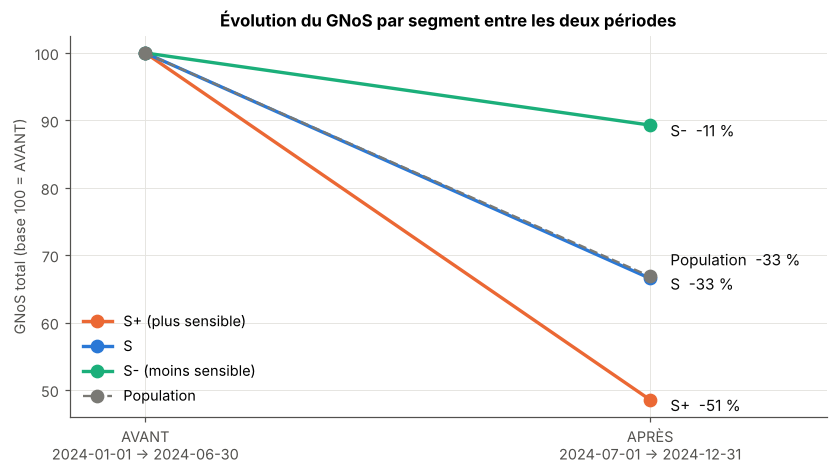

In [7]:
# 4.1 Avant → après : indice base 100 = période AVANT
fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
cle = "gnos" if METRIQUE == "gnos_total" else "gnos_par_demande"
noms = ["S+", "S", "S-", "Total"]
fins = [100 * resume.loc[s, f"{cle}_apres"] / resume.loc[s, f"{cle}_avant"] for s in noms]
etendue = max(abs(max(fins + [100]) - min(fins + [100])), 1)
for seg, fin, y_txt in zip(noms, fins, ecarter(fins, 0.07 * etendue)):
    style = dict(ls="--", lw=1.5, zorder=3) if seg == "Total" else dict(lw=2.2)
    ax.plot([0, 1], [100, fin], marker="o", ms=8, color=COULEURS[seg], **style)
    nom = "Population" if seg == "Total" else seg
    ax.annotate(f"{nom}  {fin - 100:+.0f} %", (1, fin), xytext=(1.04, y_txt), textcoords="data",
                va="center", color=ENCRE, fontsize=10)
ax.set_xticks([0, 1], [f"AVANT\n{PERIODE_AVANT[0]} → {PERIODE_AVANT[1]}",
                       f"APRÈS\n{PERIODE_APRES[0]} → {PERIODE_APRES[1]}"])
ax.set_xlim(-0.15, 1.35)
ax.set_ylabel(f"{'GNoS total' if cle == 'gnos' else 'GNoS par demande'} (base 100 = AVANT)")
ax.set_title("Évolution du GNoS par segment entre les deux périodes")
ax.legend(["S+ (plus sensible)", "S", "S- (moins sensible)", "Population"], loc="lower left", frameon=False)
plt.show()

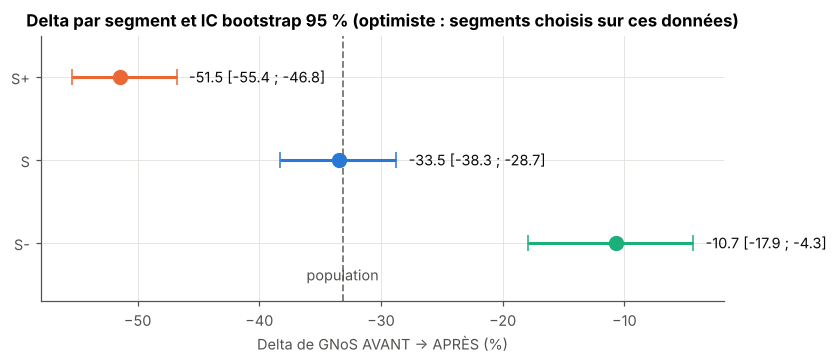

,ic_bas,mediane,ic_haut
S+,-55.4,-51.4,-46.8
S,-38.3,-33.6,-28.7
S-,-17.9,-10.8,-4.3
S- moins S+,+31.1,+40.6,+48.5
S moins S+,+10.5,+17.8,+24.4
S- moins S,+14.0,+23.0,+31.9


In [8]:
# 4.2 Delta par segment avec intervalle de confiance bootstrap 95 %
ic = ds.bootstrap(donnees, cfg, n=N_BOOTSTRAP, graine=GRAINE)
fig, ax = plt.subplots(figsize=(7.5, 3.2), layout="constrained")
for k, seg in enumerate(["S+", "S", "S-"]):
    d, lo, hi = resume.loc[seg, "delta"], ic.loc[seg, "ic_bas"], ic.loc[seg, "ic_haut"]
    ax.errorbar(d, k, xerr=[[d - lo], [hi - d]], fmt="o", ms=9, capsize=5, lw=2, color=COULEURS[seg])
    ax.annotate(f"{d:+.1f} [{lo:+.1f} ; {hi:+.1f}]", (hi, k), xytext=(8, 0),
                textcoords="offset points", va="center", color=ENCRE)
ax.axvline(resume.loc["Total", "delta"], color=COULEURS["Total"], ls="--", lw=1.2)
ax.annotate("population", (resume.loc["Total", "delta"], 2.45), color=ENCRE_2, ha="center")
ax.set_yticks(range(3), ["S+", "S", "S-"])
ax.invert_yaxis()
ax.set_ylim(2.7, -0.5)
ax.set_xlabel(f"Delta de GNoS AVANT → APRÈS ({UNITE})")
ax.set_title("Delta par segment et IC bootstrap 95 % (optimiste : segments choisis sur ces données)")
plt.show()
ic.style.format("{:+.1f}")

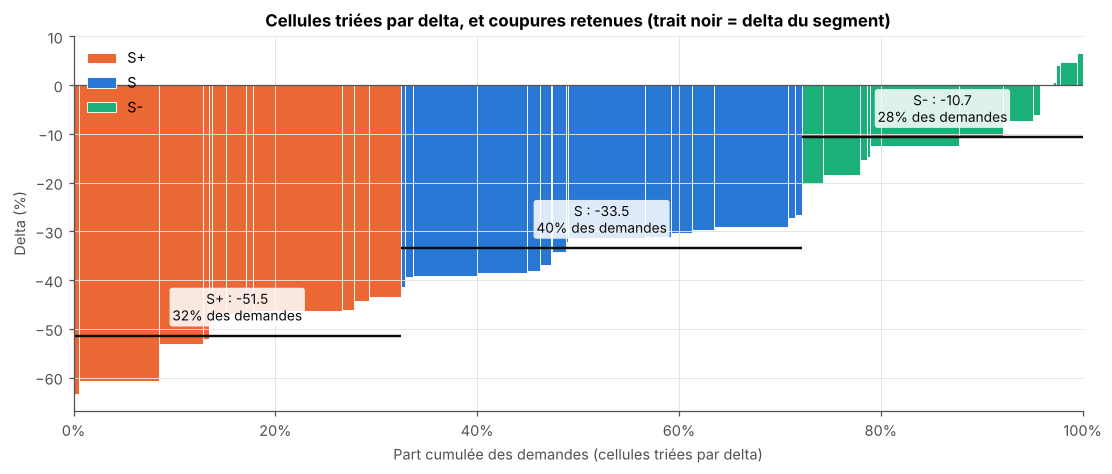

In [9]:
# 4.3 Échelle des cellules : chaque barre est une combinaison de modalités
#     largeur = poids dans la population, hauteur = delta utilisé pour le tri.
fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
largeur = cellules.n_total / cellules.n_total.sum()
gauche = largeur.cumsum() - largeur
for seg in ["S+", "S", "S-"]:
    m = cellules.segment == seg
    ax.bar(gauche[m], cellules.delta_tri[m], width=largeur[m], align="edge",
           color=COULEURS[seg], edgecolor="white", linewidth=0.6, label=seg)
    r = resume.loc[seg]
    centre = gauche[m].min() + largeur[m].sum() / 2
    ax.hlines(r.delta, gauche[m].min(), gauche[m].min() + largeur[m].sum(), color=ENCRE, lw=1.6)
    ax.annotate(f"{seg} : {r.delta:+.1f}\n{r.part_population:.0%} des demandes", (centre, r.delta),
                xytext=(0, 8), textcoords="offset points", ha="center", va="bottom", color=ENCRE,
                fontsize=9, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.axhline(0, color=ENCRE_2, lw=0.8)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Part cumulée des demandes (cellules triées par delta)")
ax.set_ylabel(f"Delta ({UNITE})")
ax.set_title("Cellules triées par delta, et coupures retenues (trait noir = delta du segment)")
ax.legend(frameon=False, loc="upper left")
plt.show()

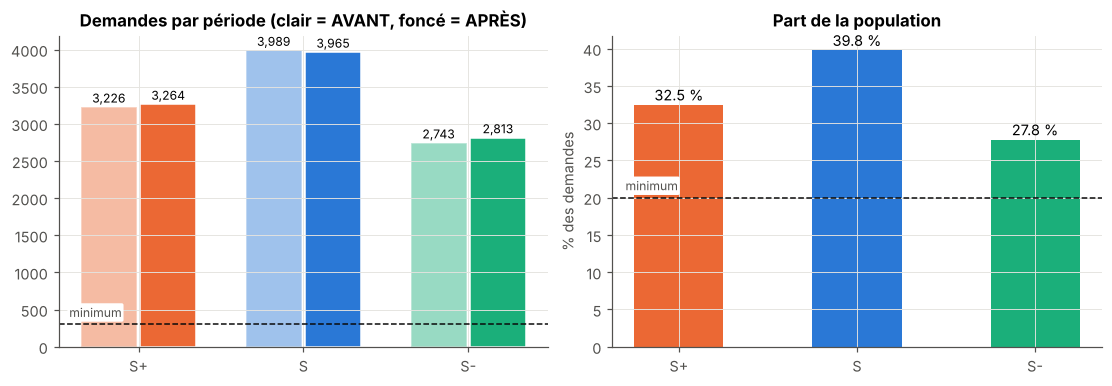

In [10]:
# 4.4 Règle 2 : chaque segment est-il assez alimenté dans chaque période ?
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
x = np.arange(3)
segs = ["S+", "S", "S-"]
for k, (periode, alpha) in enumerate([("avant", 0.45), ("apres", 1.0)]):
    n = resume.loc[segs, f"n_{periode}"]
    axes[0].bar(x + (k - 0.5) * 0.36, n, width=0.34, color=[COULEURS[s] for s in segs],
                alpha=alpha, edgecolor="white", label=periode.upper().replace("APRES", "APRÈS"))
    for xi, v in zip(x + (k - 0.5) * 0.36, n):
        axes[0].annotate(f"{v:,}", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
axes[0].axhline(EFFECTIF_MIN_SEGMENT_PAR_PERIODE, color=ENCRE, ls="--", lw=1)
axes[0].annotate("minimum", (-0.42, EFFECTIF_MIN_SEGMENT_PAR_PERIODE), xytext=(0, 3), textcoords="offset points",
                 va="bottom", ha="left", color=ENCRE_2, fontsize=8,
                 bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
axes[0].set_xticks(x, segs)
axes[0].set_title("Demandes par période (clair = AVANT, foncé = APRÈS)")
axes[1].bar(x, resume.loc[segs, "part_population"] * 100, color=[COULEURS[s] for s in segs], width=0.5)
for xi, v in zip(x, resume.loc[segs, "part_population"] * 100):
    axes[1].annotate(f"{v:.1f} %", (xi, v), xytext=(0, 3), textcoords="offset points", ha="center")
axes[1].axhline(PART_MIN_PAR_SEGMENT * 100, color=ENCRE, ls="--", lw=1)
axes[1].annotate("minimum", (-0.3, PART_MIN_PAR_SEGMENT * 100), xytext=(0, 3), textcoords="offset points",
                 va="bottom", fontsize=8, color=ENCRE_2, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
axes[1].set_xticks(x, segs)
axes[1].set_ylabel("% des demandes")
axes[1].set_title("Part de la population")
plt.show()

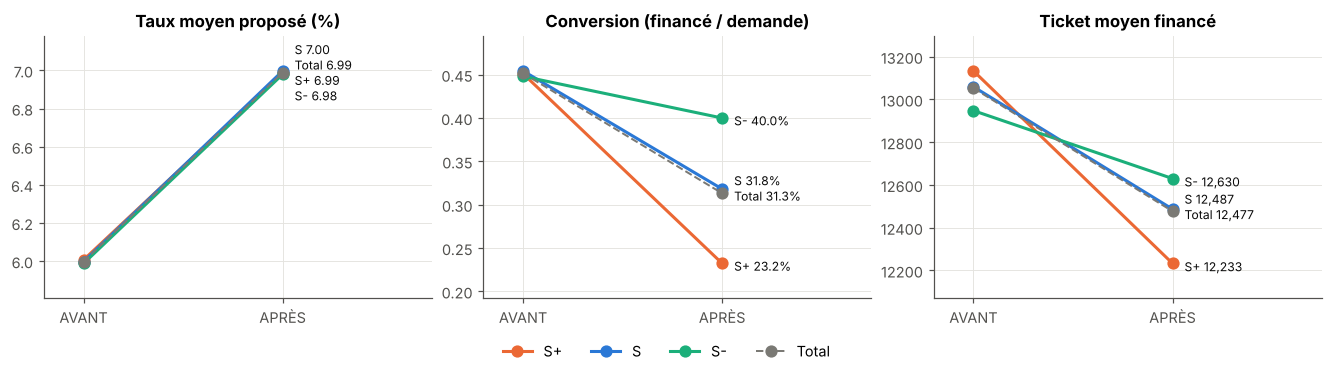

Variation du taux moyen par segment : {'S+': 0.98, 'S': 1.0, 'S-': 0.99}
Si ces variations diffèrent nettement, un écart de delta peut venir d'une hausse de prix différente, et pas d'une sensibilité différente. Comparez alors delta / variation de taux.


In [11]:
# 4.5 Le prix a-t-il bougé de la même façon pour tous ? D'où vient la baisse : volume ou ticket ?
panneaux = [p for p, c in [("taux", COLONNE_TAUX), ("conv", COLONNE_BOOKED), ("ticket", COLONNE_BOOKED)] if c]
if not panneaux:
    print("COLONNE_TAUX et COLONNE_BOOKED absentes : décomposition non disponible.")
else:
    fig, axes = plt.subplots(1, len(panneaux), figsize=(4 * len(panneaux), 3.3), layout="constrained")
    axes = np.atleast_1d(axes)
    definitions = {
        "taux": ("taux_moyen", "Taux moyen proposé (%)", "{:.2f}"),
        "conv": ("conversion", "Conversion (financé / demande)", "{:.1%}"),
        "ticket": ("ticket_moyen", "Ticket moyen financé", "{:,.0f}"),
    }
    for ax, p in zip(axes, panneaux):
        prefixe, titre, fmt = definitions[p]
        noms = ["S+", "S", "S-", "Total"]
        series = {seg: resume.loc[seg, [f"{prefixe}_avant", f"{prefixe}_apres"]].astype(float).to_numpy()
                  for seg in noms}
        fins = [series[seg][1] for seg in noms]
        tout = np.concatenate(list(series.values()))
        positions = ecarter(fins, 0.08 * (tout.max() - tout.min() or 1))
        for seg, y_txt in zip(noms, positions):
            y = series[seg]
            ax.plot([0, 1], y, marker="o", ms=7, color=COULEURS[seg], lw=2 if seg != "Total" else 1.3,
                    ls="-" if seg != "Total" else "--", label=seg)
            ax.annotate(f"{seg} {fmt.format(y[1])}", (1, y[1]), xytext=(1.06, y_txt), textcoords="data",
                        va="center", fontsize=8, color=ENCRE)
        ax.margins(y=0.18)
        ax.set_xticks([0, 1], ["AVANT", "APRÈS"])
        ax.set_xlim(-0.2, 1.75)
        ax.set_title(titre)
    poignees, libelles = axes[0].get_legend_handles_labels()
    fig.legend(poignees, libelles, loc="outside lower center", ncols=4, frameon=False)
    plt.show()
    if "delta_taux_pp" in resume:
        ecart = resume.loc[["S+", "S", "S-"], "delta_taux_pp"]
        print(f"Variation du taux moyen par segment : {ecart.round(2).to_dict()}")
        print("Si ces variations diffèrent nettement, un écart de delta peut venir d'une hausse de prix "
              "différente, et pas d'une sensibilité différente. Comparez alors delta / variation de taux.")

## 5. Robustesse : la segmentation est-elle réelle ou produite par le bruit ?

Une recherche qui **maximise** un écart en trouve toujours un, même sur des données sans signal. C'est le principal risque méthodologique.
Deux tests le contrôlent :

- **Test de permutation.** Dans chaque période, on mélange les profils sociodémographiques entre les demandes.
  Le lien profil ↔ GNoS est ainsi rompu, mais le mix de chaque période est conservé. On relance ensuite *toute* la recherche.
  Si le score réel ne dépasse pas nettement les scores obtenus par hasard, la segmentation n'est pas démontrée.
- **Placebo.** On refait l'analyse sur deux périodes **sans** changement de prix. On doit y trouver des écarts faibles et
  non significatifs. Sinon, les écarts observés relèvent d'une saisonnalité propre à certains profils, pas du prix.

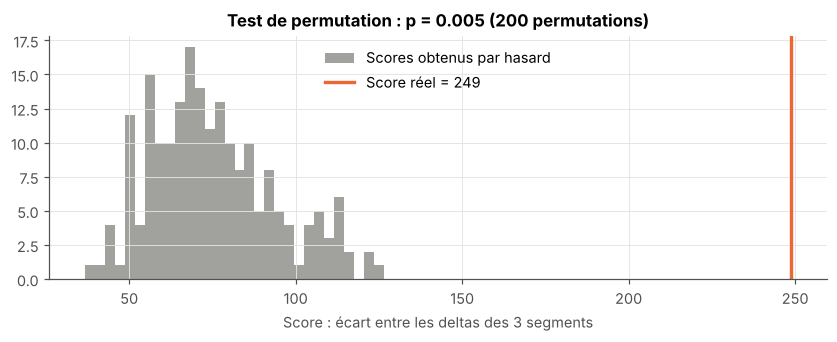

Score réel / 95e centile du hasard : 2.2x


In [12]:
observe, scores_nuls, p_valeur = ds.test_permutation(donnees, cfg, n=N_PERMUTATIONS, graine=GRAINE)
fig, ax = plt.subplots(figsize=(7.5, 3), layout="constrained")
ax.hist(scores_nuls, bins=30, color=COULEURS["Total"], alpha=0.7, label="Scores obtenus par hasard")
ax.axvline(observe, color=COULEURS["S+"], lw=2.2, label=f"Score réel = {observe:,.0f}")
ax.set_xlabel("Score : écart entre les deltas des 3 segments")
ax.set_title(f"Test de permutation : p = {p_valeur:.3f} ({N_PERMUTATIONS} permutations)")
ax.legend(frameon=False)
plt.show()
print(f"Score réel / 95e centile du hasard : {observe / np.quantile(scores_nuls, 0.95):.1f}x")

In [13]:
if LANCER_PLACEBO:
    cfg_placebo = ds.Config(**{**cfg.__dict__, "periode_avant": PLACEBO_AVANT, "periode_apres": PLACEBO_APRES})
    try:
        d_placebo = ds.preparer(brut, cfg_placebo)
        _, d_placebo, _ = ds.segmenter(d_placebo, cfg_placebo)
        obs_p, nuls_p, p_placebo = ds.test_permutation(d_placebo, cfg_placebo, n=N_PERMUTATIONS, graine=GRAINE)
        r_p = ds.synthese(d_placebo, cfg_placebo)
        print(f"PLACEBO {PLACEBO_AVANT} vs {PLACEBO_APRES} : p = {p_placebo:.3f}")
        print(r_p[["part_population", "delta"]].round(3).to_string())
        print("Attendu : p élevé et deltas proches. Un p faible ici fragilise l'interprétation 'prix'.")
    except ValueError as erreur:
        print(f"Placebo impossible : {erreur}")

PLACEBO ('2024-01-01', '2024-03-31') vs ('2024-04-01', '2024-06-30') : p = 0.741
         part_population   delta
segment                         
S+                 0.356 -14.901
S                  0.425   2.793
S-                 0.219  22.870
Total              1.000  -0.105
Attendu : p élevé et deltas proches. Un p faible ici fragilise l'interprétation 'prix'.


## 6. Composition des segments : qui est S+, S, S- ?

L'**indice** est la part d'une modalité dans le segment divisée par sa part dans la population.
Un indice > 1 signale une modalité surreprésentée, un indice < 1 une modalité sous-représentée.
Le chiffre affiché dans chaque case est la part dans le segment.

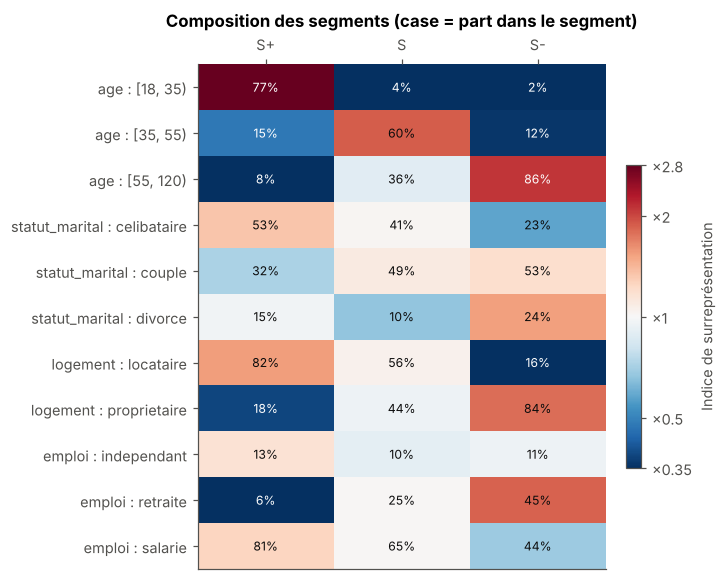

In [14]:
table_profils = ds.profils(donnees, cfg)
pivot_i = table_profils.pivot_table(index=["variable", "modalite"], columns="segment", values="indice")
pivot_p = table_profils.pivot_table(index=["variable", "modalite"], columns="segment", values="part_segment")
pivot_i, pivot_p = pivot_i[["S+", "S", "S-"]], pivot_p[["S+", "S", "S-"]]
ordre = [(v, m) for v in VARIABLES_SOCIODEMO for m in pivot_i.loc[v].index]
pivot_i, pivot_p = pivot_i.loc[ordre], pivot_p.loc[ordre]

fig, ax = plt.subplots(figsize=(6.5, 0.36 * len(pivot_i) + 1.2), layout="constrained")
valeurs = np.log2(pivot_i.clip(lower=0.125).to_numpy())
image = ax.imshow(valeurs, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
for (r, c), v in np.ndenumerate(pivot_p.to_numpy()):
    ax.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=8,
            color="white" if abs(valeurs[r, c]) > 1 else ENCRE)
ax.set_xticks(range(3), ["S+", "S", "S-"])
ax.xaxis.tick_top()
ax.set_yticks(range(len(pivot_i)), [f"{v} : {m}" for v, m in pivot_i.index])
ax.grid(False)
barre = fig.colorbar(image, ax=ax, shrink=0.6)
barre.set_ticks([-1.5, -1, 0, 1, 1.5], labels=["×0.35", "×0.5", "×1", "×2", "×2.8"])
barre.set_label("Indice de surreprésentation")
ax.set_title("Composition des segments (case = part dans le segment)")
plt.show()

In [15]:
# Définition EXACTE de chaque segment : la liste des combinaisons de modalités
for seg in ["S+", "S", "S-"]:
    c = cellules.loc[cellules.segment == seg].sort_values("n_total", ascending=False)
    print(f"\n=== {seg} : {len(c)} combinaisons, {int(c.n_total.sum()):,} demandes ===")
    print(c[VARIABLES_SOCIODEMO + ["n_avant", "n_apres", "delta_tri", "niveau_repli"]]
          .head(15).to_string(index=False, float_format=lambda v: f"{v:+.1f}"))


=== S+ : 12 combinaisons, 6,490 demandes ===
      age statut_marital     logement      emploi  n_avant  n_apres  delta_tri                            niveau_repli
 [18, 35)         couple    locataire     salarie      860      915      -46.4                        cellule complète
 [18, 35)    celibataire    locataire     salarie      802      787      -60.7                        cellule complète
 [35, 55)    celibataire proprietaire     salarie      459      421      -53.1                        cellule complète
 [18, 35)        divorce    locataire     salarie      287      338      -43.4                        cellule complète
[55, 120)    celibataire    locataire    retraite      212      194      -47.0                        cellule complète
 [18, 35)         couple    locataire independant      154      148      -44.2                        cellule complète
 [18, 35)    celibataire    locataire independant      127      155      -47.1                        cellule complète
 [

### Texte prêt à coller dans un LLM

Le texte ci-dessous contient **uniquement des agrégats** : aucun identifiant ni ligne client.
Il est aussi enregistré dans `description_pour_llm.md`. Copiez-le dans un LLM pour obtenir une description
rédigée de chaque profil. Avant tout usage hors de l'équipe, vérifiez que les effectifs ne permettent pas de réidentifier des personnes.

In [16]:
texte = ds.texte_pour_llm(cellules, resume, table_profils, cfg)
print(texte)

# Contexte

Crédit à la consommation. Changement de prix (hausse des taux) entre la période AVANT (2024-01-01 → 2024-06-30) et la période APRÈS (2024-07-01 → 2024-12-31).
Indicateur : GNoS total, delta relatif (%). Delta de la population totale : -33.2 %.
Trois segments ont été formés à partir des variables : age, statut_marital, logement, emploi. S+ = le plus sensible au prix, S = intermédiaire, S- = le moins sensible.

# Segment S+

- Poids : 32.5% des demandes ; 3226 avant, 3264 après.
- Delta : -51.5 % (écart à la population : -18.3).
- Variation du taux moyen : +0.98 point.

Modalités par variable (part dans le segment vs population, indice) :
- age : [18, 35) 77% vs 27% (×2.83) ; [35, 55) 15% vs 32% (×0.47) ; [55, 120) 8% vs 41% (×0.20)
- statut_marital : celibataire 53% vs 40% (×1.33) ; divorce 15% vs 16% (×0.96) ; couple 32% vs 45% (×0.72)
- logement : locataire 82% vs 53% (×1.54) ; proprietaire 18% vs 47% (×0.38)
- emploi : salarie 81% vs 64% (×1.25) ; independant 13% vs 11% (

In [17]:
from datetime import datetime

dossier = Path(racine, f"{DOSSIER_RESULTATS}_{datetime.now():%Y%m%d_%H%M%S}")
ds.sauvegarder(dossier, cfg, cellules, resume, ic, table_profils, texte)
print(f"Exporté dans {dossier}")
for f in sorted(dossier.iterdir()):
    print(" -", f.name)

Exporté dans /home/user/credit-price-segmentation/results/delta_gnos_20261117_123832
 - cellules_et_segments.csv
 - config.json
 - description_pour_llm.md
 - intervalles_bootstrap.csv
 - profils_segments.csv
 - synthese_segments.csv


## 7. Lecture critique et limites

- **Delta ≠ effet causal du prix.** Entre deux périodes, le GNoS bouge aussi avec la saisonnalité, le marketing,
  la concurrence, la politique d'octroi ou les taux de marché (BCE). L'**écart entre segments** est plus
  informatif que le delta brut, selon une logique proche de la double différence (*difference-in-differences*).
  Il suppose toutefois que, sans changement de prix, tous les segments auraient évolué de la même façon
  (*tendances parallèles*). Le placebo teste partiellement cette hypothèse.
- **Exposition au prix.** Si la hausse de taux n'a pas été la même pour tous (4.5), comparez delta / variation de taux.
  On se rapproche alors d'une semi-élasticité.
- **Biais de sélection.** Les segments sont choisis pour maximiser l'écart, donc les écarts affichés sont optimistes.
  Pour une conclusion solide, figez les cellules → segments sur un premier changement de prix et vérifiez-les sur un autre,
  ou sur un autre produit.
- **Descriptions marginales.** « Plus de jeunes » et « plus de locataires » ne veut pas dire « plus de jeunes locataires ».
  La liste exacte des combinaisons (section 6) lève cette ambiguïté.
- **Conformité.** L'âge, le statut marital ou le logement peuvent décrire les profils.
  Leur usage pour **différencier les prix** doit être validé : directive (UE) 2023/2225 sur le crédit aux consommateurs,
  législation anti-discrimination, interdiction de tarifer selon le genre, RGPD. Il faut aussi documenter le traitement équitable des clients.
- **Volume vs valeur.** `gnos_total` capte la baisse du nombre de demandes et la baisse de conversion.
  `gnos_par_demande` les sépare. Comparer les deux métriques indique si la sensibilité joue sur l'entrée dans le
  tunnel (demande) ou sur la décision finale (booking).